# Haykin Ch.6.9 — GSC/MVDR adaptive beamforming

5-element half-wavelength array、SNR=10 dB、INR=40 dB。比較 20/50/100 adaptation snapshots、target direction 與 response resolution；用 blocking matrix 的 broadcasting 取代大型 diagonal matrix。

來源：`Haykin-Chap6.9-adative-MVDR.ipynb`。所有資料與結果留在記憶體，圖表使用共用深色風格。

執行順序：設定 → 參數與資料 → 模型與訓練 → 圖表與數值摘要。

## 1. Setup

In [ ]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Geometry and factories

In [ ]:
from adsp import beamforming as bf

n_trials, seed, n_sensors, mu = 100, 622, 5, 1e-6
directions = np.linspace(-1, 1, 1000)
patterns = {}
gains = {}

## 3. Shared snapshots and unified Monte Carlo

In [ ]:
for target_direction in (-0.15, -0.1, -0.05):
  target = bf.steering(n_sensors, target_direction)
  interferer = bf.steering(n_sensors, 0.0)
  for n_samples in (20, 50, 100):
    make_data = partial(bf.snapshots, n_samples, target_vector=target, interference_vector=interferer,
                        target_power=10.0, interference_power=10000.0, noise_var=1.0)
    models = {"GSC LMS": partial(bf.SnapshotLMS, n_features=n_sensors - 1, mu=mu)}
    results = training.compare(models, make_data, n_trials=n_trials, seed=seed, transforms={"GSC LMS": bf.gsc_batch})
    result = results["GSC LMS"]
    adaptive = result.w_mean[-1]
    weights = bf.gsc_weights(adaptive, target)
    label = f"target={target_direction}, snapshots={n_samples}"
    response = bf.response(weights, directions)
    patterns[label] = (directions, np.abs(response)**2)
    gains[label] = abs(np.vdot(weights, target))**2
    assert np.allclose(gains[label], 1.0)
print("Target-direction gains:", gains)

## 4. Mean-weight beam patterns and response resolution

In [ ]:
plot.lines(patterns, scale="db", xlabel="sin(θ)", ylabel="Gain (dB)", title="GSC response of ensemble mean weights")
plot.show()
resolutions = {}
for resolution in (200, 500, 1000):
  theta = np.linspace(-1, 1, resolution)
  resolutions[f"{resolution} response samples"] = (theta, abs(bf.response(weights, theta))**2)
plot.lines(resolutions, scale="db", xlabel="sin(θ)", ylabel="Gain (dB)", title="Sampling a fixed array response")
plot.show()

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

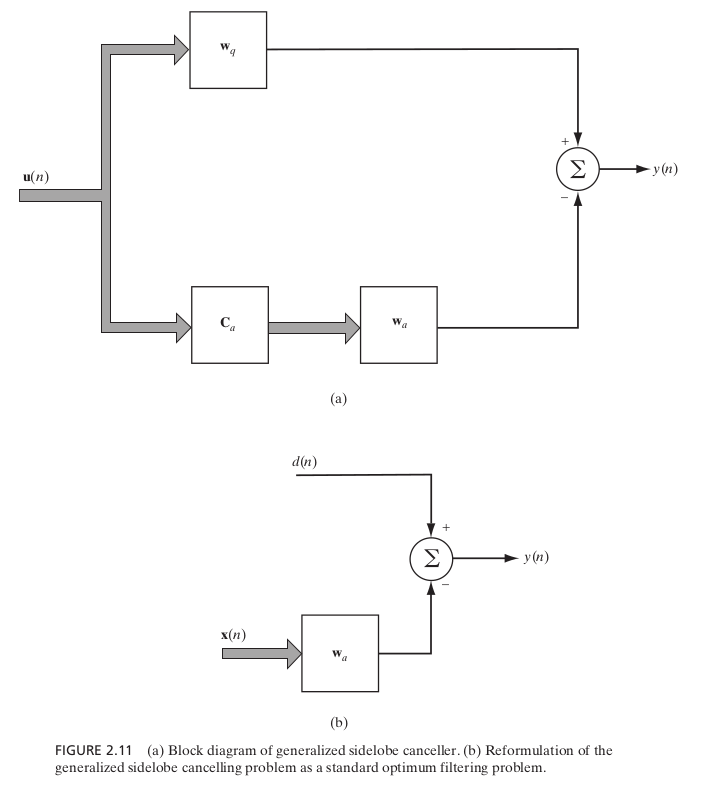